# Введение 

## 1. 5 примеров применения машинного обучения в жизни:

1) Системы рекомендации. Они помогают быстрее находить необходимое в интернете, предлагают то, что интересно пользователю.
2) ML в здравоохранении. Помогают выявить болезни на разных стадиях, 
3) Чат-боты и умные помощники. В отличие от человека не нужен отдых. Мгновенный ответ. 
4) Беспилотные автомобили. Снижение аварийности, экономия времени и ресурсов
5) Прогноз движения. Показывают время поездки, лучшие варианты, что помогает выбрать наиболее оптимальный и удобный маршрут.

## 2. 
1. Обучение с учителем(Задача регрессии, тк стоимость непрерывная величина)
2. Обучение с учителем(Бинарная класиффикация, тк вернет "да" или "нет")
3. Обучение с учителем(Задача регрессии, тк нужно предсказать время)
4. Обучение с учителем(Многоклассовая классификация, тк лекарств много)
5. Если есть данные уже были о промо-акциях, то подойдет обучение с учителем(регрессия(ожидаемая прибыль) или бинарная классификация(подойдет ли акция да или нет)), если нет, то без учителя кластеризация(группировка клиентов по покупкам)
6. Обучение с учителем(Бинарная классификация, есть ли дефект)
7. Обучение с подкреплением(тк нужно получать мнения клиентов) 
8. Обучение с учителем(Бинарная класиффикация, открыл или нет страницу)
9. Обучение без учителя(Кластеризация)
10. Обучение с учителем(Бинарная класиффикация, если были данные о причинах)
11. Обучение с учителем(Многоклассовая класиффикация), Обучение без учителя(Кластеризация)
12.Обучение с учителем(Классификация, регрессия)
13. Обработка естественного языка(NLP), Генерация текста
14.Компьютерное зрение, обучение с подкреплением
15.Обучние с учителем(Регрессия, Классификация)

## 3.
Разница между Multiclass и Multilabel в том, что у первого один объект пренадлежит ровно одному классу, а у второго один объект может пренадлежать нескольким классам

## 4.
Задача прогнозирования цен не жилье является задачей регрессии, потому что цена непрерывная величина, но ее можно свести к задаче многоклассовой классификации, например, если разделить цены на классы и предсказывать в какой она попадет.

Импорт библиотек

In [ ]:
import pandas as pd
import numpy as np
import sklearn
import lightgbm
import scipy
import statsmodels 
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error
from sklearn.model_selection import train_test_split

: 

In [532]:
df_train = pd.read_json('data/train.json')
df_train

,bathrooms,bedrooms,building_id,created,description,display_address,features,latitude,listing_id,longitude,manager_id,photos,price,street_address,interest_level
4,1.0,1,8579a0b0d54db803821a35a4a615e97a,2016-06-16 05:55:27,Spacious 1 Bedroom 1 Bathroom in Williamsburg!...,145 Borinquen Place,"[Dining Room, Pre-War, Laundry in Building, Di...",40.7108,7170325,-73.9539,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/7170325_3bb5ac84...,2400,145 Borinquen Place,medium
6,1.0,2,b8e75fc949a6cd8225b455648a951712,2016-06-01 05:44:33,BRAND NEW GUT RENOVATED TRUE 2 BEDROOMFind you...,East 44th,"[Doorman, Elevator, Laundry in Building, Dishw...",40.7513,7092344,-73.9722,955db33477af4f40004820b4aed804a0,[https://photos.renthop.com/2/7092344_7663c19a...,3800,230 East 44th,low
9,1.0,2,cd759a988b8f23924b5a2058d5ab2b49,2016-06-14 15:19:59,**FLEX 2 BEDROOM WITH FULL PRESSURIZED WALL**L...,East 56th Street,"[Doorman, Elevator, Laundry in Building, Laund...",40.7575,7158677,-73.9625,c8b10a317b766204f08e613cef4ce7a0,[https://photos.renthop.com/2/7158677_c897a134...,3495,405 East 56th Street,medium
10,1.5,3,53a5b119ba8f7b61d4e010512e0dfc85,2016-06-24 07:54:24,A Brand New 3 Bedroom 1.5 bath ApartmentEnjoy ...,Metropolitan Avenue,[],40.7145,7211212,-73.9425,5ba989232d0489da1b5f2c45f6688adc,[https://photos.renthop.com/2/7211212_1ed4542e...,3000,792 Metropolitan Avenue,medium
15,1.0,0,bfb9405149bfff42a92980b594c28234,2016-06-28 03:50:23,Over-sized Studio w abundant closets. Availabl...,East 34th Street,"[Doorman, Elevator, Fitness Center, Laundry in...",40.7439,7225292,-73.9743,2c3b41f588fbb5234d8a1e885a436cfa,[https://photos.renthop.com/2/7225292_901f1984...,2795,340 East 34th Street,low
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
124000,1.0,3,92bbbf38baadfde0576fc496bd41749c,2016-04-05 03:58:33,There is 700 square feet of recently renovated...,W 171 Street,"[Elevator, Dishwasher, Hardwood Floors]",40.8433,6824800,-73.9396,a61e21da3ba18c7a3d54cfdcc247e1f8,[https://photos.renthop.com/2/6824800_0682be16...,2800,620 W 171 Street,low
124002,1.0,2,5565db9b7cba3603834c4aa6f2950960,2016-04-02 02:25:31,"2 bedroom apartment with updated kitchen, rece...",Broadway,"[Common Outdoor Space, Cats Allowed, Dogs Allo...",40.8198,6813268,-73.9578,8f90e5e10e8a2d7cf997f016d89230eb,[https://photos.renthop.com/2/6813268_1e6fcc32...,2395,3333 Broadway,medium
124004,1.0,1,67997a128056ee1ed7d046bbb856e3c7,2016-04-26 05:42:03,No Brokers Fee * Never Lived 1 Bedroom 1 Bathr...,210 Brighton 15th St,"[Dining Room, Elevator, Pre-War, Laundry in Bu...",40.5765,6927093,-73.9554,a10db4590843d78c784171a107bdacb4,[https://photos.renthop.com/2/6927093_93a52104...,1850,210 Brighton 15th St,medium
124008,1.0,2,3c0574a740154806c18bdf1fddd3d966,2016-04-19 02:47:33,Wonderful Bright Chelsea 2 Bedroom apartment o...,West 21st Street,"[Pre-War, Laundry in Unit, Dishwasher, No Fee,...",40.7448,6892816,-74.0017,c3cd45f4381ac371507090e9ffabea80,[https://photos.renthop.com/2/6892816_1a8d087a...,4195,350 West 21st Street,medium


In [533]:
df_train.columns.tolist()

['bathrooms',
 'bedrooms',
 'building_id',
 'created',
 'description',
 'display_address',
 'features',
 'latitude',
 'listing_id',
 'longitude',
 'manager_id',
 'photos',
 'price',
 'street_address',
 'interest_level']

Целевая переменная - это столбец price

In [534]:
df_train.info()

<class 'pandas.core.frame.DataFrame'>
Index: 49352 entries, 4 to 124009
Data columns (total 15 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   bathrooms        49352 non-null  float64
 1   bedrooms         49352 non-null  int64  
 2   building_id      49352 non-null  object 
 3   created          49352 non-null  object 
 4   description      49352 non-null  object 
 5   display_address  49352 non-null  object 
 6   features         49352 non-null  object 
 7   latitude         49352 non-null  float64
 8   listing_id       49352 non-null  int64  
 9   longitude        49352 non-null  float64
 10  manager_id       49352 non-null  object 
 11  photos           49352 non-null  object 
 12  price            49352 non-null  int64  
 13  street_address   49352 non-null  object 
 14  interest_level   49352 non-null  object 
dtypes: float64(3), int64(3), object(9)
memory usage: 6.0+ MB


In [535]:
df_train.describe()

,bathrooms,bedrooms,latitude,listing_id,longitude,price
count,49352.00000,49352.000000,49352.000000,4.935200e+04,49352.000000,4.935200e+04
mean,1.21218,1.541640,40.741545,7.024055e+06,-73.955716,3.830174e+03
std,0.50142,1.115018,0.638535,1.262746e+05,1.177912,2.206687e+04
min,0.00000,0.000000,0.000000,6.811957e+06,-118.271000,4.300000e+01
25%,1.00000,1.000000,40.728300,6.915888e+06,-73.991700,2.500000e+03
50%,1.00000,1.000000,40.751800,7.021070e+06,-73.977900,3.150000e+03
75%,1.00000,2.000000,40.774300,7.128733e+06,-73.954800,4.100000e+03
max,10.00000,8.000000,44.883500,7.753784e+06,0.000000,4.490000e+06


In [536]:
num_df = df_train.select_dtypes(['int64', 'float64'])
num_df.corr()

,bathrooms,bedrooms,latitude,listing_id,longitude,price
bathrooms,1.000000,0.533446,-0.009657,0.000776,0.010393,0.069661
bedrooms,0.533446,1.000000,-0.004745,0.011968,0.006892,0.051788
latitude,-0.009657,-0.004745,1.000000,0.001712,-0.966807,-0.000707
listing_id,0.000776,0.011968,0.001712,1.000000,-0.000907,0.008090
longitude,0.010393,0.006892,-0.966807,-0.000907,1.000000,-0.000087
price,0.069661,0.051788,-0.000707,0.008090,-0.000087,1.000000


select_columns = ['', ]

In [537]:
select_columns = ['bathrooms', 'bedrooms', 'interest_level', 'price']
df = df_train[select_columns].copy()
df

,bathrooms,bedrooms,interest_level,price
4,1.0,1,medium,2400
6,1.0,2,low,3800
9,1.0,2,medium,3495
10,1.5,3,medium,3000
15,1.0,0,low,2795
...,...,...,...,...
124000,1.0,3,low,2800
124002,1.0,2,medium,2395
124004,1.0,1,medium,1850
124008,1.0,2,medium,4195


(array([4.9344e+04, 4.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 2.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([4.30000000e+01, 8.98421400e+04, 1.79641280e+05, 2.69440420e+05,
        3.59239560e+05, 4.49038700e+05, 5.38837840e+05, 6.28636980e+05,
        7.18436120e+05, 8.08235260e+05, 8.98034400e+05, 9.87833540e+05,
        1.07763268e+06, 1.16743182e+06, 1.25723096e+06, 1.34703010e+06,
        1.43682924e+06, 1.5266

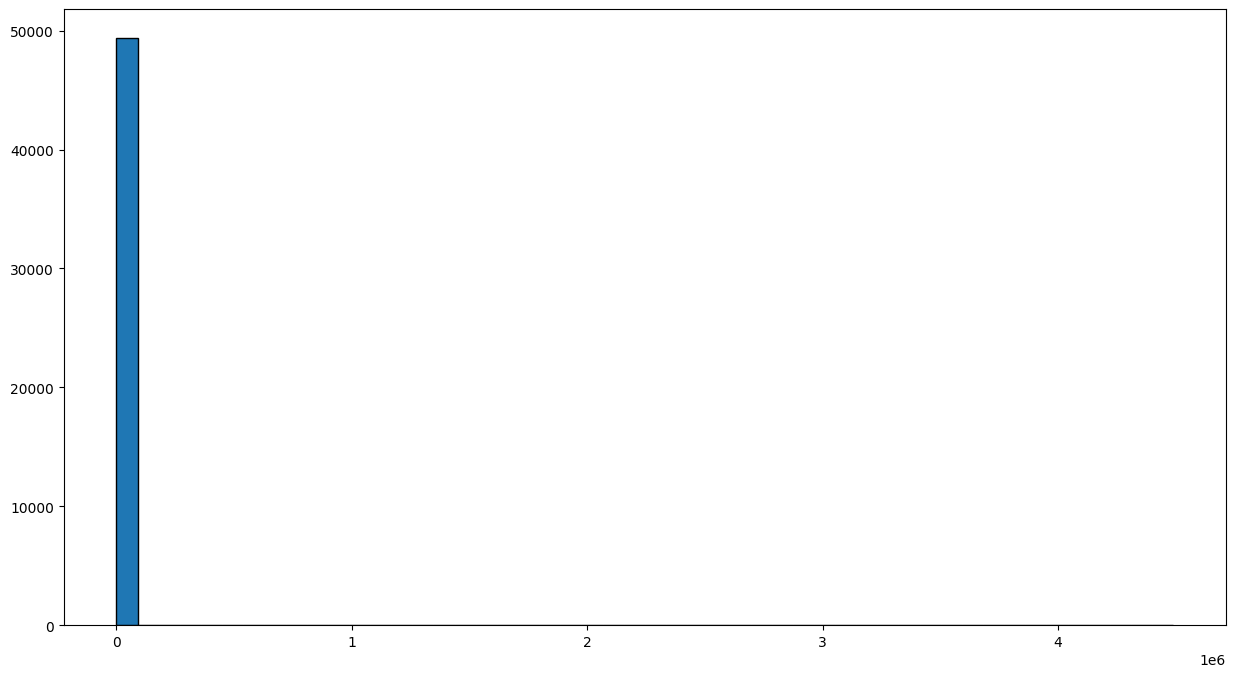

In [538]:
plt.figure(figsize=(15, 8))
plt.hist(df['price'], bins=50, edgecolor='black', linewidth=1)

Все точки в нуле

{'whiskers': [<matplotlib.lines.Line2D at 0x7773945432b0>,
 'caps': [<matplotlib.lines.Line2D at 0x7773945437f0>,
 'boxes': [<matplotlib.lines.Line2D at 0x777394542fb0>],
 'medians': [<matplotlib.lines.Line2D at 0x777394543820>],
 'fliers': [<matplotlib.lines.Line2D at 0x777394543ac0>],
 'means': []}

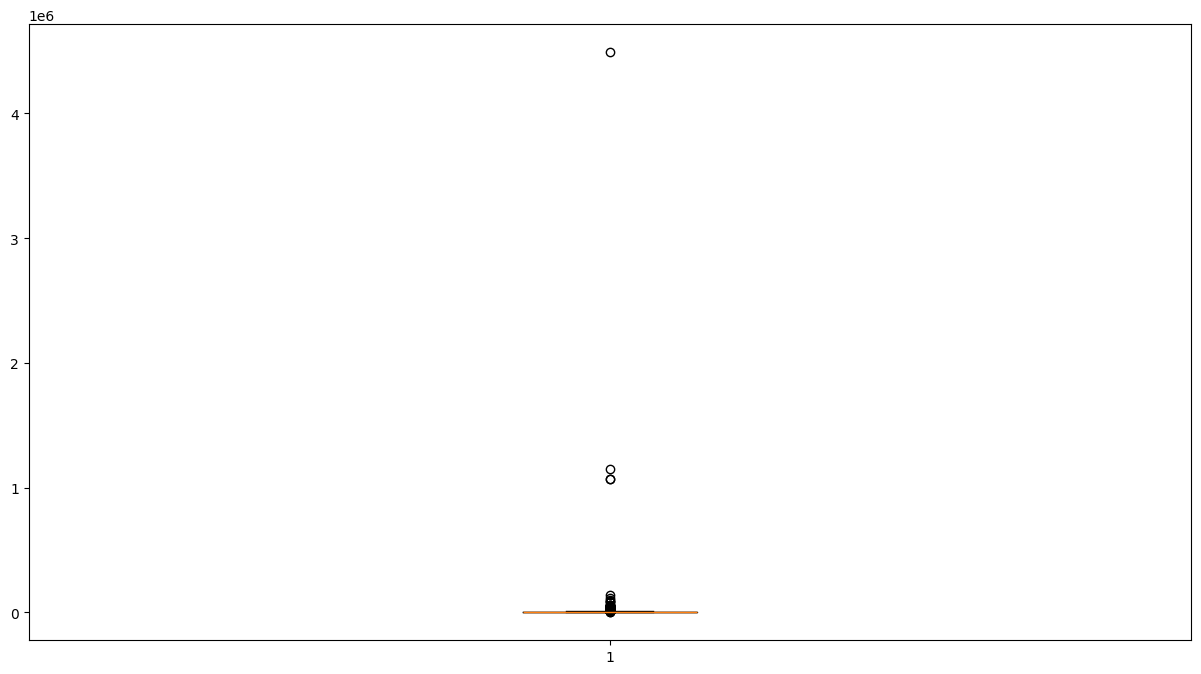

In [539]:
plt.figure(figsize=(15, 8))
plt.boxplot(df['price'])

In [540]:
low_percentile = df['price'].quantile(0.01)
high_percentile = df['price'].quantile(0.99)
df_clean = df[(df['price'] > low_percentile) & (df['price'] < high_percentile)]
df_clean

,bathrooms,bedrooms,interest_level,price
4,1.0,1,medium,2400
6,1.0,2,low,3800
9,1.0,2,medium,3495
10,1.5,3,medium,3000
15,1.0,0,low,2795
...,...,...,...,...
124000,1.0,3,low,2800
124002,1.0,2,medium,2395
124004,1.0,1,medium,1850
124008,1.0,2,medium,4195


(array([1236., 2316., 2902., 4252., 4199., 4442., 3904., 4091., 3520.,
        2559., 2689., 1239., 1222., 1621.,  887., 1153.,  726.,  898.,
         521.,  744.,  491.,  461.,  193.,  364.,  131.,  149.,  173.,
         109.,  210.,   61.,   95.,   48.,  112.,   35.,   62.,   21.,
         131.,   10.,   11.,   30.,   25.,   72.,   19.,   39.,   17.,
          72.,    7.,   48.,   13.,   13.]),
 array([ 1485. ,  1715.2,  1945.4,  2175.6,  2405.8,  2636. ,  2866.2,
         3096.4,  3326.6,  3556.8,  3787. ,  4017.2,  4247.4,  4477.6,
         4707.8,  4938. ,  5168.2,  5398.4,  5628.6,  5858.8,  6089. ,
         6319.2,  6549.4,  6779.6,  7009.8,  7240. ,  7470.2,  7700.4,
         7930.6,  8160.8,  8391. ,  8621.2,  8851.4,  9081.6,  9311.8,
         9542. ,  9772.2, 10002.4, 10232.6, 10462.8, 10693. , 10923.2,
        11153.4, 11383.6, 11613.8, 11844. , 12074.2, 12304.4, 12534.6,
        12764.8, 12995. ]),
 <BarContainer object of 50 artists>)

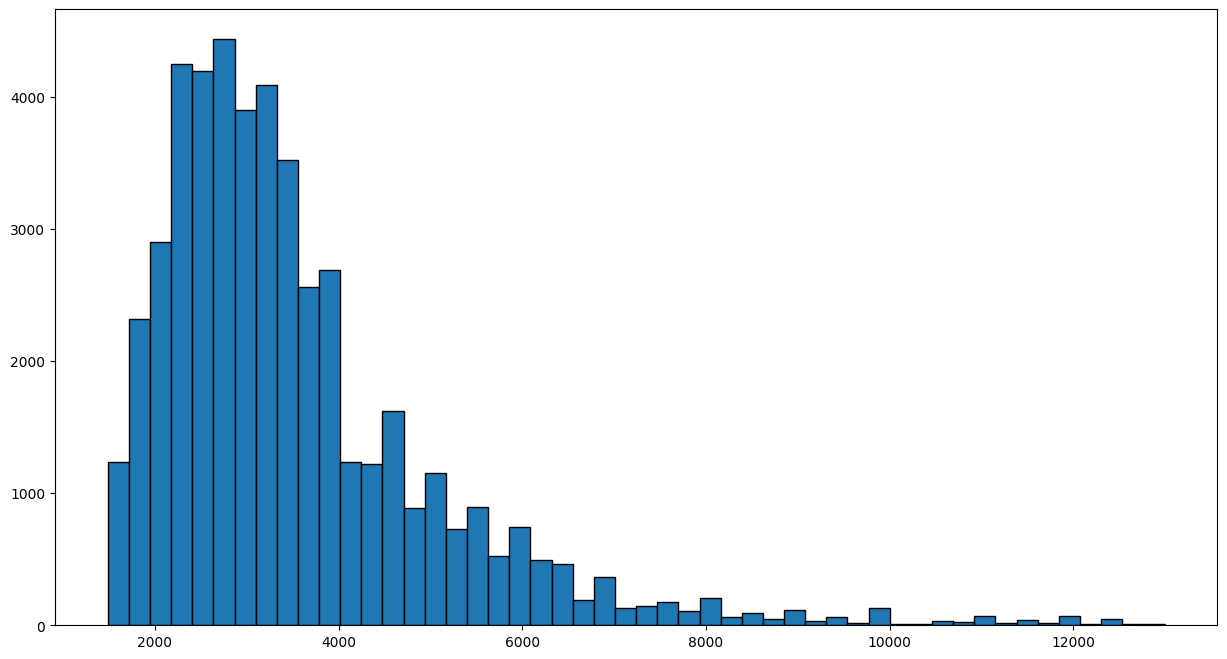

In [541]:
plt.figure(figsize=(15, 8))
plt.hist(df_clean['price'], bins=50, edgecolor='black', linewidth=1)

In [542]:
df_clean['interest_level'].info()

<class 'pandas.core.series.Series'>
Index: 48343 entries, 4 to 124009
Series name: interest_level
Non-Null Count  Dtype 
--------------  ----- 
48343 non-null  object
dtypes: object(1)
memory usage: 755.4+ KB


In [543]:
unique_values = df_clean['interest_level'].value_counts()
unique_values

interest_level
low       33672
medium    11114
high       3557
Name: count, dtype: int64

In [544]:
encodes = {'low': 1, 'medium': 2,'high': 3}
df_clean['interest_level'] = df['interest_level'].map(encodes)
df_clean    

/tmp/ipykernel_122095/3099721621.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['interest_level'] = df['interest_level'].map(encodes)


,bathrooms,bedrooms,interest_level,price
4,1.0,1,2,2400
6,1.0,2,1,3800
9,1.0,2,2,3495
10,1.5,3,2,3000
15,1.0,0,1,2795
...,...,...,...,...
124000,1.0,3,1,2800
124002,1.0,2,2,2395
124004,1.0,1,2,1850
124008,1.0,2,2,4195


(array([3.1300e+02, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        3.9422e+04, 0.0000e+00, 6.4500e+02, 0.0000e+00, 0.0000e+00,
        7.6600e+03, 0.0000e+00, 2.7700e+02, 0.0000e+00, 0.0000e+00,
        7.4500e+02, 0.0000e+00, 7.0000e+01, 0.0000e+00, 0.0000e+00,
        1.5900e+02, 0.0000e+00, 2.9000e+01, 0.0000e+00, 0.0000e+00,
        2.0000e+01, 0.0000e+00, 5.0000e+00, 0.0000e+00, 0.0000e+00,
        4.0000e+00, 0.0000e+00, 1.0000e+00, 0.0000e+00, 0.0000e+00,
        1.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 1.0000e+00]),
 array([ 0. ,  0.2,  0.4,  0.6,  0.8,  1. ,  1.2,  1.4,  1.6,  1.8,  2. ,
         2.2,  2.4,  2.6,  2.8,  3. ,  3.2,  3.4,  3.6,  3.8,  4. ,  4.2,
         4.4,  4.6,  4.8,  5. ,  5.2,  5.4,  5.6,  5.8,  6. ,  6.2,  6.4,
         6.6,  6.8,  7. ,  7.2,  7.4,  7.6,  7.8,  8. ,  8.2,  8.4,  8.6,
         8.8,  9. ,  9

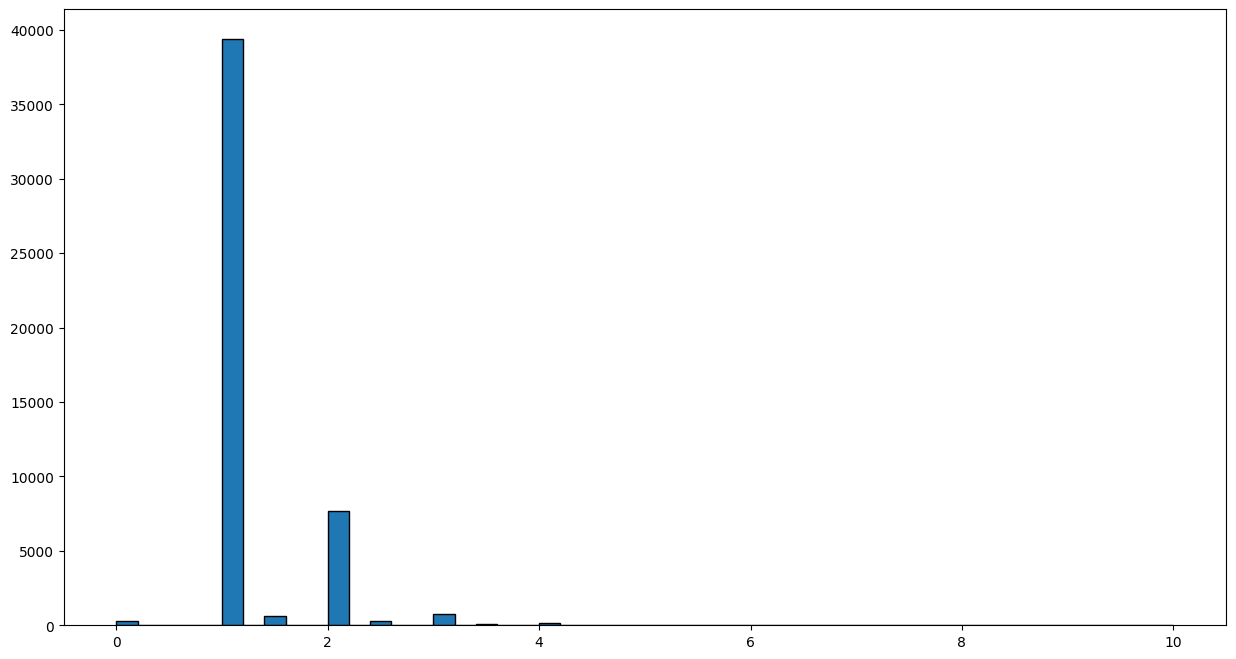

In [545]:
plt.figure(figsize=(15, 8))
plt.hist(df['bathrooms'], bins=50, edgecolor='black', linewidth=1)

(array([9.4750e+03, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 1.5752e+04, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 1.4623e+04, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 7.2760e+03, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        1.9290e+03, 0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 2.4700e+02, 0.0000e+00, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 4.6000e+01, 0.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 2.0000e+00, 0.0000e+00,
        0.0000e+00, 0.0000e+00, 0.0000e+00, 0.0000e+00, 2.0000e+00]),
 array([0.  , 0.16, 0.32, 0.48, 0.64, 0.8 , 0.96, 1.12, 1.28, 1.44, 1.6 ,
        1.76, 1.92, 2.08, 2.24, 2.4 , 2.56, 2.72, 2.88, 3.04, 3.2 , 3.36,
        3.52, 3.68, 3.84, 4.  , 4.16, 4.32, 4.48, 4.64, 4.8 , 4.96, 5.12,
        5.28, 5.44, 5.6 , 5.76, 5.92, 6.08, 6.24, 6.4 , 6.56, 6.72, 6.88,
        7.04, 7.2 , 7.

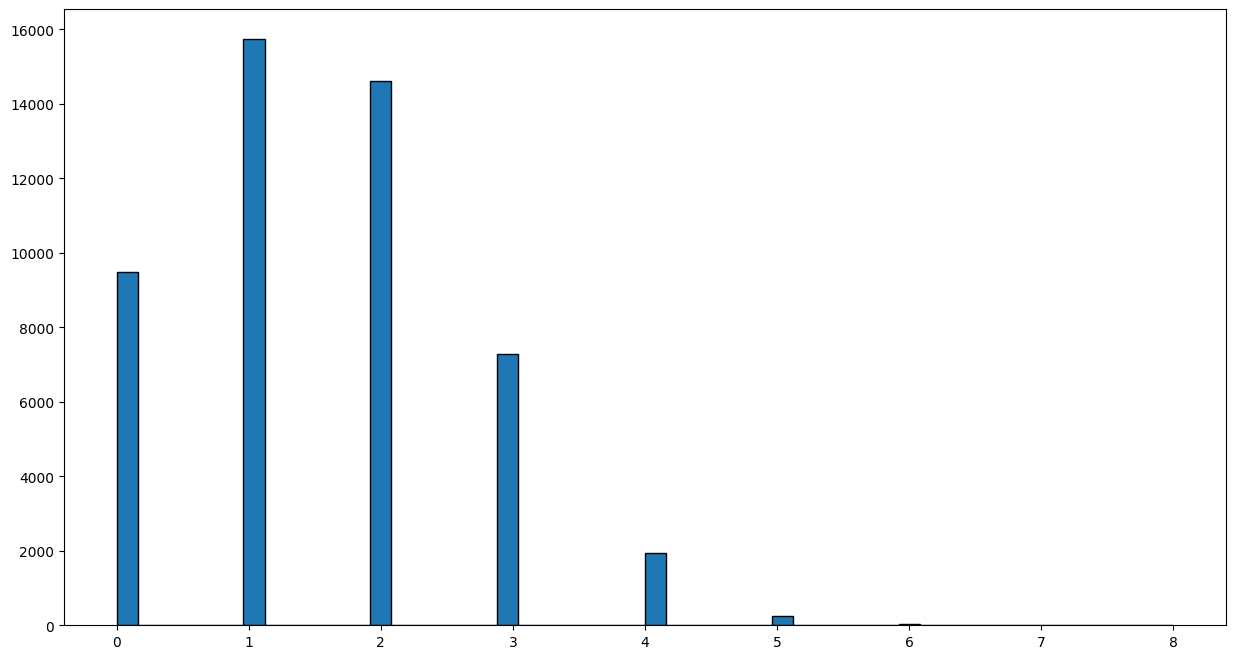

In [546]:
plt.figure(figsize=(15, 8))
plt.hist(df['bedrooms'], bins=50, edgecolor='black', linewidth=1)

In [547]:
corr_matrix = df_clean.corr()
corr_matrix

,bathrooms,bedrooms,interest_level,price
bathrooms,1.000000,0.517200,-0.062819,0.670808
bedrooms,0.517200,1.000000,0.051282,0.547310
interest_level,-0.062819,0.051282,1.000000,-0.199652
price,0.670808,0.547310,-0.199652,1.000000


<Axes: >

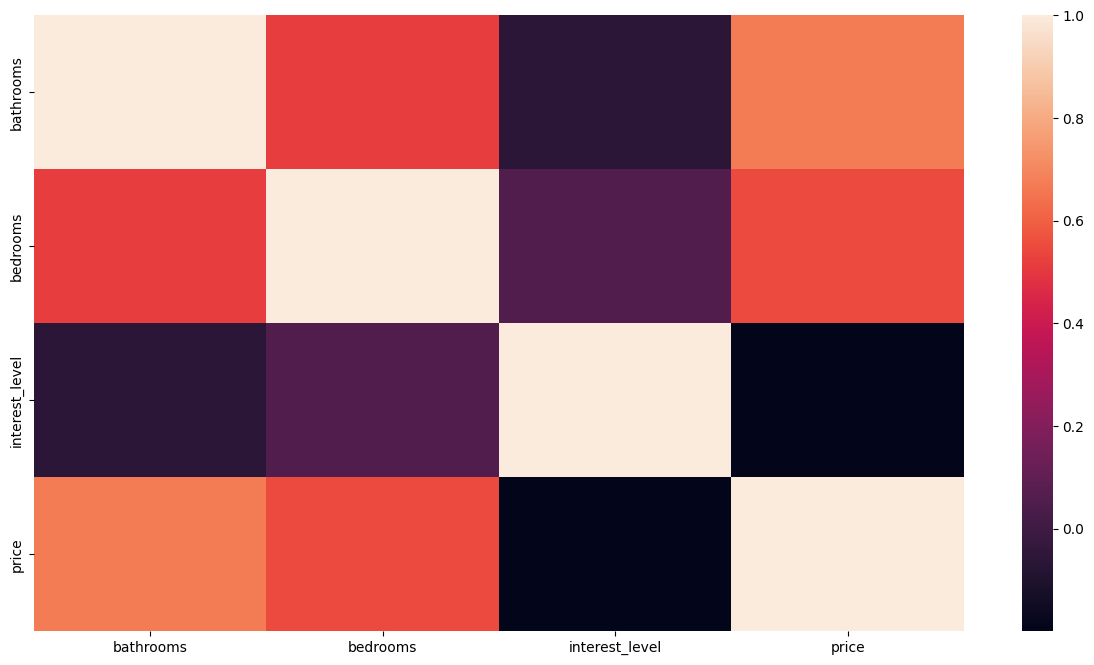

In [548]:
plt.figure(figsize=(15, 8))
sns.heatmap(corr_matrix)

Text(0.5, 1.0, 'price and interest level')

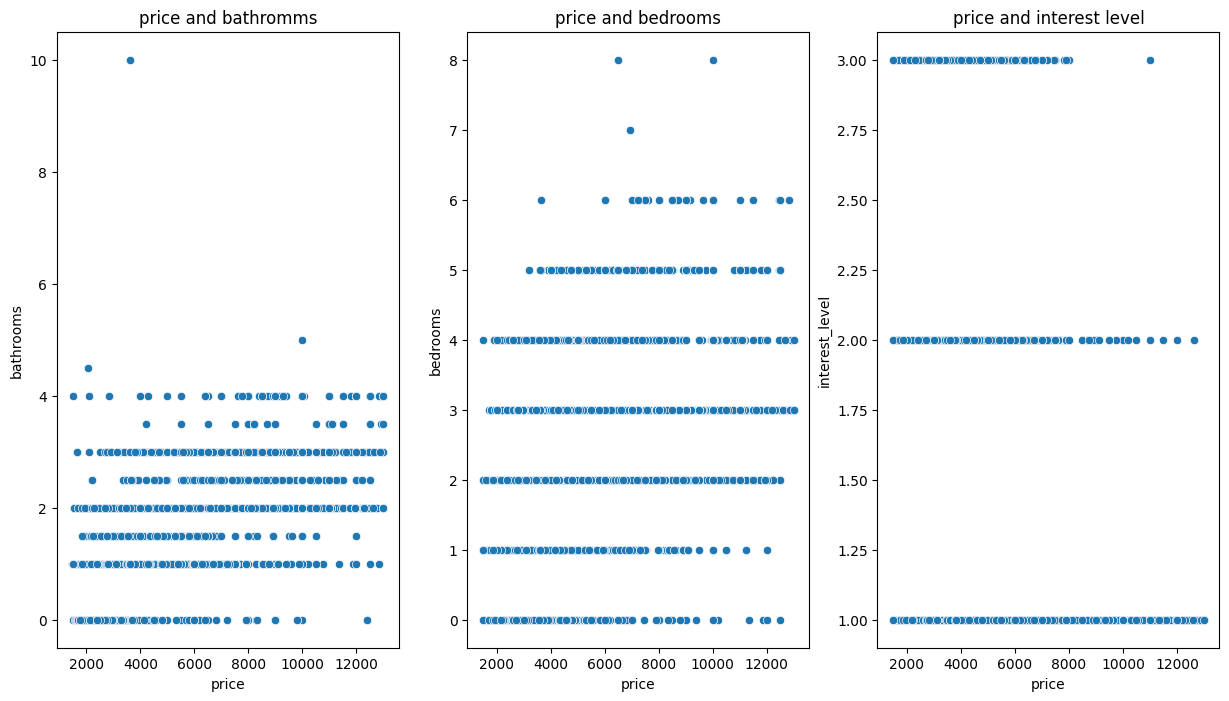

In [549]:
fig, axes = plt.subplots(1, 3, figsize=(15, 8))
sns.scatterplot(data=df_clean, x='price', y='bathrooms', ax=axes[0])
axes[0].set_title('price and bathromms')

sns.scatterplot(data=df_clean, x='price', y='bedrooms', ax=axes[1])
axes[1].set_title('price and bedrooms')

sns.scatterplot(data=df_clean, x='price', y='interest_level', ax=axes[2])
axes[2].set_title('price and interest level')

In [550]:
df_clean['bathromms_squared'] = df_clean['bathrooms'] ** 2
df_clean['bedrooms_squared'] = df_clean['bedrooms'] ** 2
df_clean['interest_level_squared'] = df_clean['interest_level'] ** 2

new_corr_matrix = df_clean.corr()
new_corr_matrix

/tmp/ipykernel_122095/712601098.py:1: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['bathromms_squared'] = df_clean['bathrooms'] ** 2
/tmp/ipykernel_122095/712601098.py:2: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  df_clean['bedrooms_squared'] = df_clean['bedrooms'] ** 2
/tmp/ipykernel_122095/712601098.py:3: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: htt

,bathrooms,bedrooms,interest_level,price,bathromms_squared,bedrooms_squared,interest_level_squared
bathrooms,1.000000,0.517200,-0.062819,0.670808,0.955906,0.548426,-0.061785
bedrooms,0.517200,1.000000,0.051282,0.547310,0.478497,0.928282,0.046777
interest_level,-0.062819,0.051282,1.000000,-0.199652,-0.067757,0.047048,0.987937
price,0.670808,0.547310,-0.199652,1.000000,0.646949,0.544612,-0.194344
bathromms_squared,0.955906,0.478497,-0.067757,0.646949,1.000000,0.521951,-0.065815
bedrooms_squared,0.548426,0.928282,0.047048,0.544612,0.521951,1.000000,0.042725
interest_level_squared,-0.061785,0.046777,0.987937,-0.194344,-0.065815,0.042725,1.000000


<Axes: >

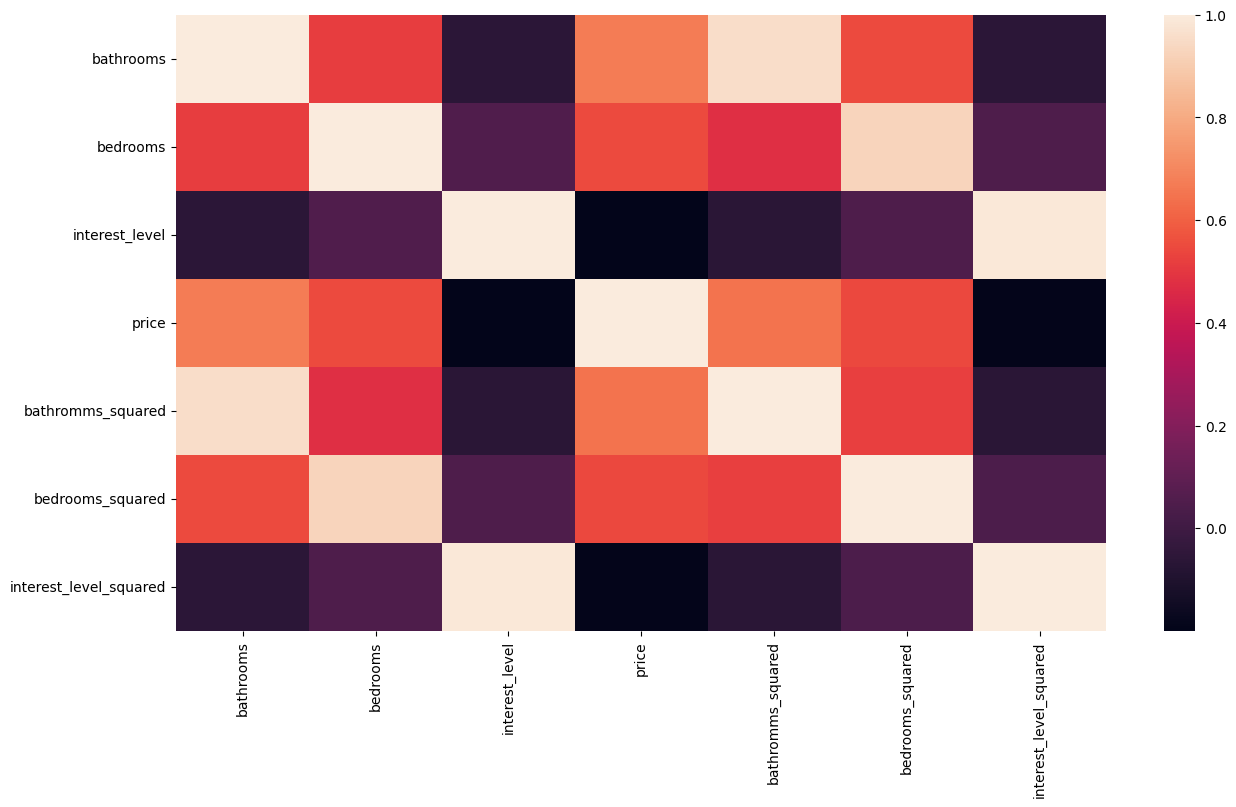

In [551]:
plt.figure(figsize=(15, 8))
sns.heatmap(new_corr_matrix)

In [552]:
X_train = df_clean[['bathrooms', 'bedrooms']]
y_train = df_clean['price']

test_df = pd.read_json('data/test.json')

low_percentile = test_df['price'].quantile(0.01)
high_percentile = test_df['price'].quantile(0.99)
test_df = test_df[(test_df['price'] >= low_percentile) & (test_df['price'] <= high_percentile)]

test_df = test_df[~test_df['bathrooms'].isin([20.0, 112.0])]
X_test = test_df[['bathrooms', 'bedrooms']]
y_test = test_df['price']

from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

poly = PolynomialFeatures(degree=10)
X_train_poly = poly.fit_transform(X_train_scaled)
X_test_poly = poly.transform(X_test_scaled)

In [553]:
result_MAE = pd.DataFrame(columns=['model','train','test'])
result_RMSE = pd.DataFrame(columns=['model','train','test'])

In [554]:
result_MAE = pd.DataFrame(columns=['model','train','test'])
result_RMSE = pd.DataFrame(columns=['model','train','test'])

In [555]:
lr = LinearRegression().fit(X_train_poly, y_train)
y_train_pred_lr = lr.predict(X_train_poly)
lr_train_mae = mean_absolute_error(y_train, y_train_pred_lr)
lr_train_mae

756.0913369676097

In [556]:
lr_train_rmse = np.sqrt(mean_squared_error(y_train_pred_lr, y_train))
lr_train_rmse

np.float64(1075.016457422405)

In [557]:
y_test_pred_lr = lr.predict(X_test_poly)
lr_test_mae = mean_absolute_error(y_test, y_test_pred_lr)
lr_test_mae

1210.2307489743555

In [558]:
lr_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_lr))
lr_test_rmse

np.float64(69275.0445827211)

In [559]:
result_MAE = pd.concat([result_MAE, pd.DataFrame([{
    'model': 'linear_regression',
    'train': lr_train_mae,
    'test': lr_test_mae,
}])], ignore_index=True)
result_MAE

/tmp/ipykernel_122095/2172033206.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result_MAE = pd.concat([result_MAE, pd.DataFrame([{


,model,train,test
0,linear_regression,756.091337,1210.230749


In [560]:
result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{
    'model': 'linear_regression',
    'train': lr_train_rmse,
    'test': lr_test_rmse,
}])], ignore_index=True)
result_RMSE

/tmp/ipykernel_122095/3944508101.py:1: FutureWarning: The behavior of DataFrame concatenation with empty or all-NA entries is deprecated. In a future version, this will no longer exclude empty or all-NA columns when determining the result dtypes. To retain the old behavior, exclude the relevant entries before the concat operation.
  result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{


,model,train,test
0,linear_regression,1075.016457,69275.044583


In [561]:
from sklearn.tree import DecisionTreeRegressor
dt = DecisionTreeRegressor(random_state=21).fit(X_train_poly, y_train)
y_train_pred_dt = dt.predict(X_train_poly)
y_test_pred_dt = dt.predict(X_test_poly)

dt_train_mae = mean_absolute_error(y_train, y_train_pred_dt)
dt_train_rmse = np.sqrt(mean_squared_error(y_train, y_train_pred_dt))
dt_test_mae = mean_absolute_error(y_test, y_test_pred_dt)
dt_test_rmse = np.sqrt(mean_squared_error(y_test, y_test_pred_dt))

In [562]:
result_MAE = pd.concat([result_MAE, pd.DataFrame([{
    'model': 'decision_tree',
    'train': dt_train_mae,
    'test': dt_test_mae,
}])], ignore_index=True)
result_MAE

,model,train,test
0,linear_regression,756.091337,1210.230749
1,decision_tree,753.675997,759.140684


In [563]:
result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{
    'model': 'decision_tree',
    'train': dt_train_rmse,
    'test': dt_test_rmse,
}])], ignore_index=True)
result_RMSE

,model,train,test
0,linear_regression,1075.016457,69275.044583
1,decision_tree,1070.598967,1080.826888


In [564]:
mean_train = y_train.mean()
mean_test = y_test.mean()

median_train = y_train.median()
median_test = y_test.median()

mean_train_mae = mean_absolute_error(y_train, [mean_train] * len(y_train))
mean_train_rmse = np.sqrt(mean_squared_error(y_train, [mean_train] * len(y_train)))

mean_test_mae = mean_absolute_error(y_test, [mean_test] * len(y_test))
mean_test_rmse = np.sqrt(mean_squared_error(y_test, [mean_test] * len(y_test)))


median_train_mae = mean_absolute_error(y_train, [median_train] * len(y_train))
median_train_rmse = np.sqrt(mean_squared_error(y_train, [median_train] * len(y_train)))

median_test_mae = mean_absolute_error(y_test, [median_test] * len(y_test))
median_test_rmse = np.sqrt(mean_squared_error(y_test, [median_test] * len(y_test)))

In [565]:
result_MAE = pd.concat([result_MAE, pd.DataFrame([{
    'model': 'naive_mean',
    'train': mean_train_mae,
    'test': mean_test_mae,
}])], ignore_index=True)
result_MAE

,model,train,test
0,linear_regression,756.091337,1210.230749
1,decision_tree,753.675997,759.140684
2,naive_mean,1134.361473,1135.622432


In [566]:
result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{
    'model': 'naive_mean',
    'train': mean_train_rmse,
    'test': mean_test_rmse,
}])], ignore_index=True)
result_RMSE

,model,train,test
0,linear_regression,1075.016457,69275.044583
1,decision_tree,1070.598967,1080.826888
2,naive_mean,1585.609099,1590.105076


In [567]:
result_MAE = pd.concat([result_MAE, pd.DataFrame([{
    'model': 'naive_median',
    'train': median_train_mae,
    'test': median_test_mae,
}])], ignore_index=True)
result_MAE

,model,train,test
0,linear_regression,756.091337,1210.230749
1,decision_tree,753.675997,759.140684
2,naive_mean,1134.361473,1135.622432
3,naive_median,1082.220859,1084.262317


In [568]:
result_RMSE = pd.concat([result_RMSE, pd.DataFrame([{
    'model': 'naive_median',
    'train': median_train_rmse,
    'test': median_test_rmse,
}])], ignore_index=True)
result_RMSE

,model,train,test
0,linear_regression,1075.016457,69275.044583
1,decision_tree,1070.598967,1080.826888
2,naive_mean,1585.609099,1590.105076
3,naive_median,1631.719953,1635.381127
